# Probability calibration and stability of KPI explanations

Md Forhadul Islam, London

This is my independent Dota 2 adaptation of the approach of Fazilat Hojaji,
Robert E. McIlroy, Antoine Dupuy, Gianpaolo Pedroni, Adam J. Toth and Mark J. Campbell.
Their original League of Legends paper is https://doi.org/10.1016/j.chbr.2025.100718.
It is not an exact reproduction of their numerical results. The Betty dataset is
published by wolframko using Valve replays and STRATZ data. Sources, licences and
the literature tracker are recorded in the project documentation.

I explain each step before the code and interpret the output afterwards. All
displayed experimental results come from saved calculations. Reading them does
not train a new model or choose an approach using the final test outcomes.


## Find the saved study

A path tells Python where a file lives. JSON stores labelled evidence. A DataFrame is a table with named columns. This setup reads existing results; it cannot change trained weights or the test partition.

In [1]:
from pathlib import Path  # Represent folders consistently on Windows and other systems.
import sys  # Make the shared project modules available to this notebook.
import json  # Read saved evidence with its original field names.
import pandas as pd  # Display numerical records as labelled tables.
from IPython.display import display, Image, Markdown  # Show readable tables, figures and notes.
ROOT = Path.cwd().resolve()  # Begin from the notebook execution folder.
if ROOT.name == "notebooks":  # Jupyter normally starts within the notebook folder.
    ROOT = ROOT.parent  # Move up once to reach the shared project directory.
assert (ROOT / "src").is_dir(), "Open this notebook from the project or notebooks folder."
sys.path.insert(0, str(ROOT / "src"))  # Import the same scientific code used by terminal runs.
def evidence(filename):  # Keep evidence loading consistent across the notebook.
    return json.loads((ROOT / "outputs/results" / filename).read_text(encoding="utf-8"))  # Decode one saved result.
summary = evidence("D_summary.json")  # Read the completed study without recomputing final predictions.


## Can a correct ranking still have poor confidence?

Yes. Ranking and confidence are different properties. Temperature scaling divides the model's log odds by one positive fitted number. A distinct calibration period fits that number. Both raw and adjusted probabilities were prespecified for reporting, so an unhelpful adjustment is still shown.

,model,probability,brier_mean,brier_sd,log_loss_mean,log_loss_sd
8,logistic,raw,0.172629,0.000000,0.510833,0.000000
9,logistic,temperature,0.172629,0.000000,0.510764,0.000000
10,neural_network,raw,0.175458,0.000742,0.517282,0.002556
11,neural_network,temperature,0.175467,0.000771,0.517118,0.002464
12,random_forest,raw,0.174145,0.000350,0.513546,0.000479
13,random_forest,temperature,0.174022,0.000369,0.513491,0.000484
14,xgboost,raw,0.175974,0.000117,0.517088,0.000449
15,xgboost,temperature,0.175962,0.000119,0.516950,0.000434


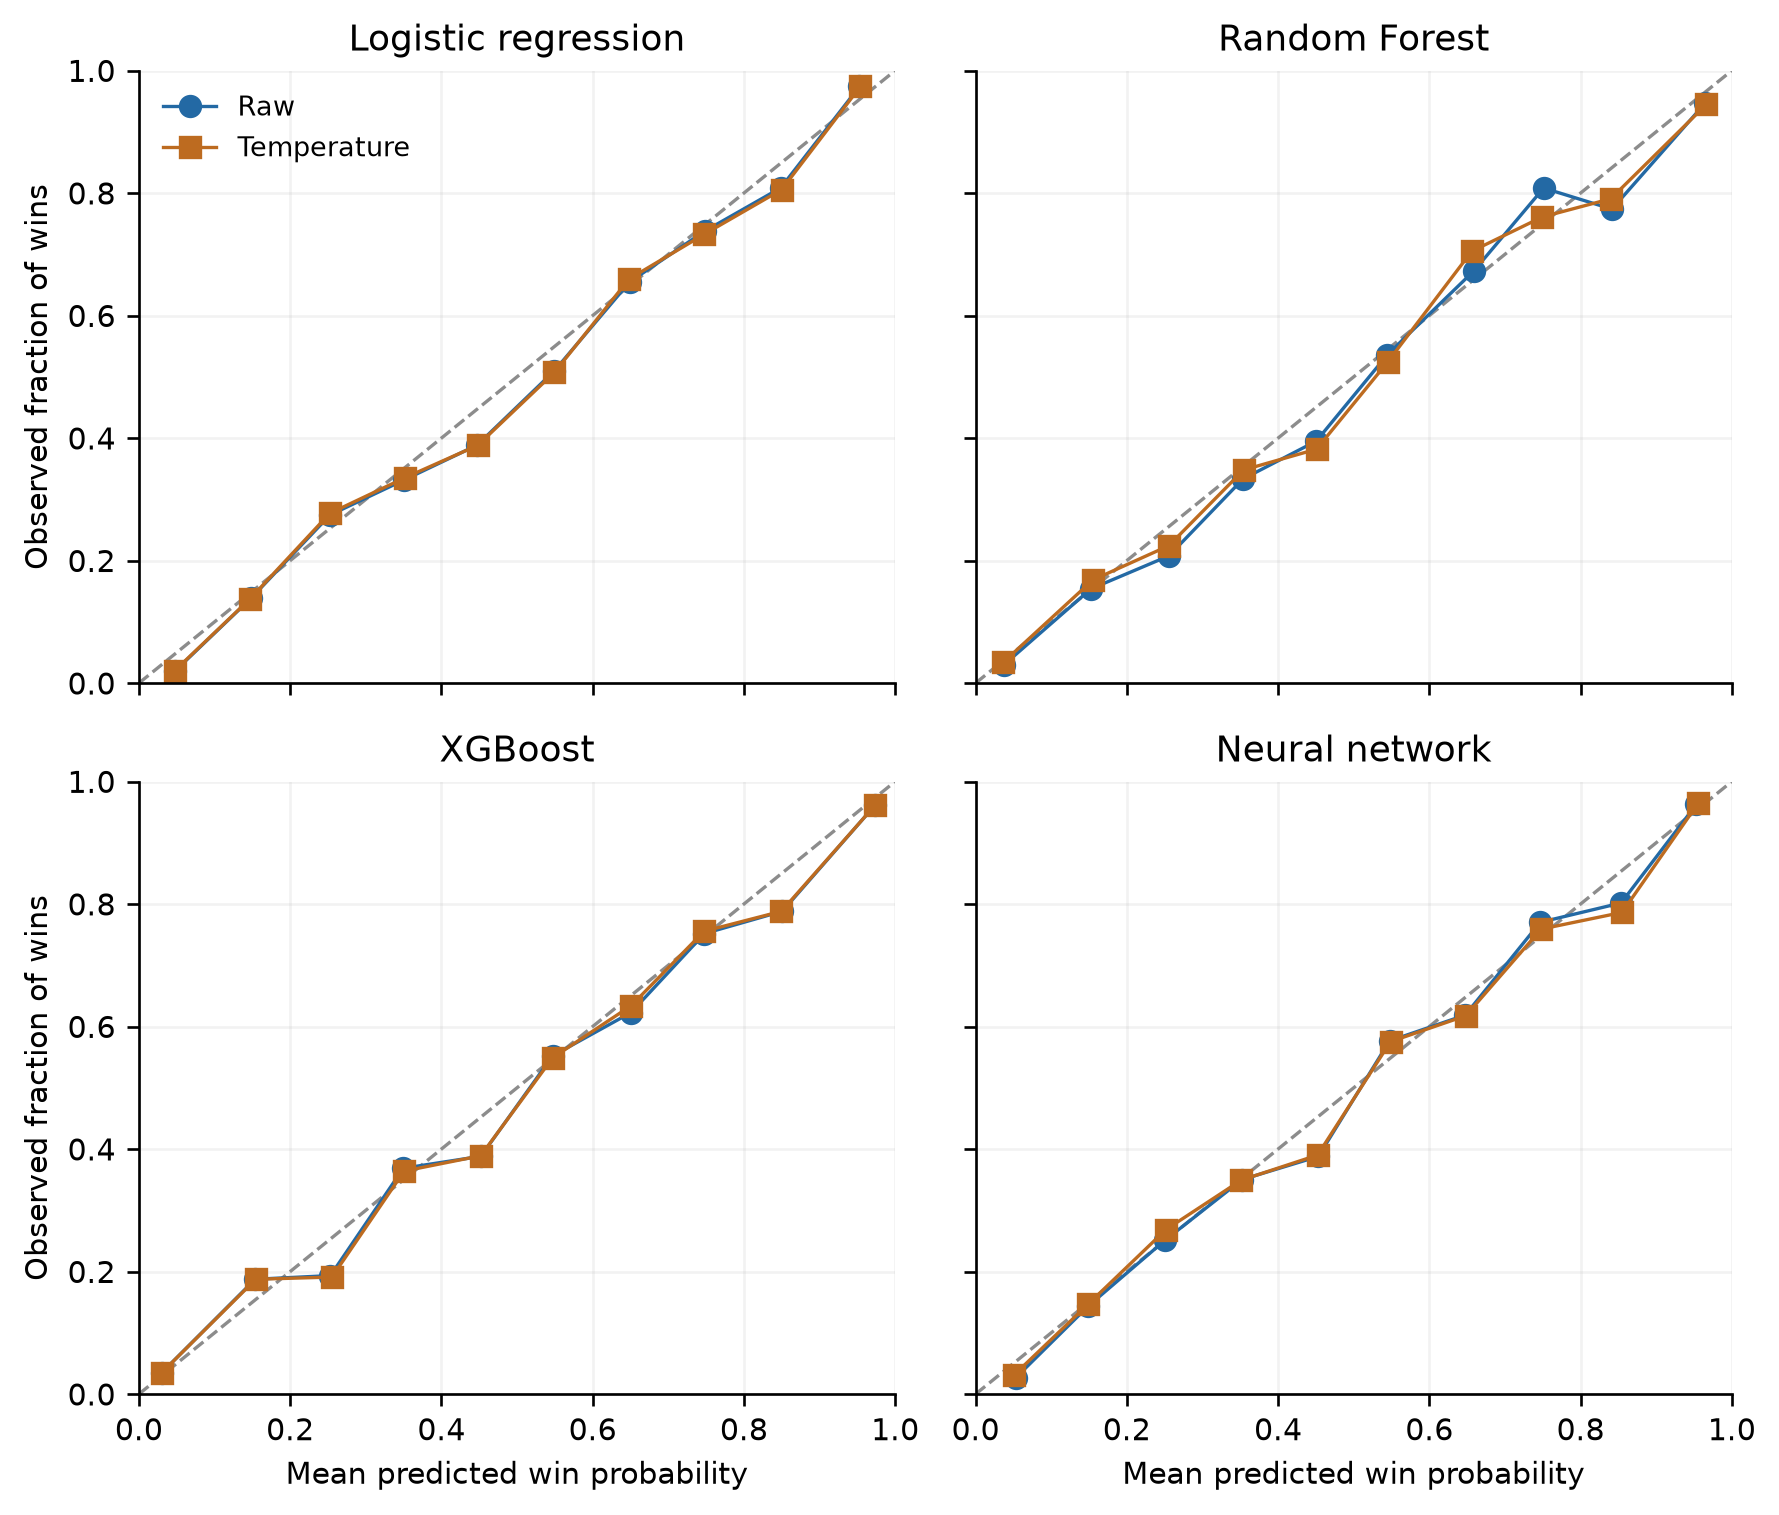

In [2]:
table = pd.DataFrame(summary["test_table"])  # Use the same final predictions for both versions.
display(table.loc[table.horizon_seconds == 1200, ["model", "probability", "brier_mean", "brier_sd", "log_loss_mean", "log_loss_sd"]].round(6))  # Report probability losses, including unsuccessful adjustments.
display(Image(filename=str(ROOT / "outputs/figures/D_calibration.png")))  # Display observed win frequencies against predicted confidence.

A reliability diagram groups predictions into probability bins. Sparse bins can be noisy, so the bin counts are saved in D_calibration_bins.json. Temperature scaling is not guaranteed to improve an unseen period, especially when the calibration sample is small or the distribution changes.

## What does SHAP explain?

SHAP attributes a model prediction relative to a reference distribution of training examples. Mean absolute SHAP summarises predictive influence, not causal impact. Exact linear and tree explainers and a deep explainer are used for the corresponding models. Their output units differ, so I compare ranks across model families rather than treating magnitudes as equivalent.

logistic             log odds
xgboost              log odds
neural_network         logits
random_forest     probability
Name: Explanation units, dtype: str

,horizon_seconds,model,feature,mean_rank,mean_absolute_shap,fixed_model_top3_frequency
40,1200,logistic,assists_diff,6.000000,0.046601,0.000000
41,1200,logistic,denies_diff,10.000000,0.006399,0.000000
42,1200,logistic,hp_diff,5.000000,0.061650,0.000000
43,1200,logistic,is_alive_diff,2.000000,0.168354,1.000000
44,1200,logistic,kills_diff,9.000000,0.006480,0.000000
45,1200,logistic,last_hits_diff,7.000000,0.041790,0.000000
46,1200,logistic,level_diff,8.000000,0.032221,0.000000
47,1200,logistic,net_worth_diff,1.000000,0.860083,1.000000
48,1200,logistic,towers_alive_diff,4.000000,0.081016,0.001000
49,1200,logistic,xp_diff,3.000000,0.099068,0.999000


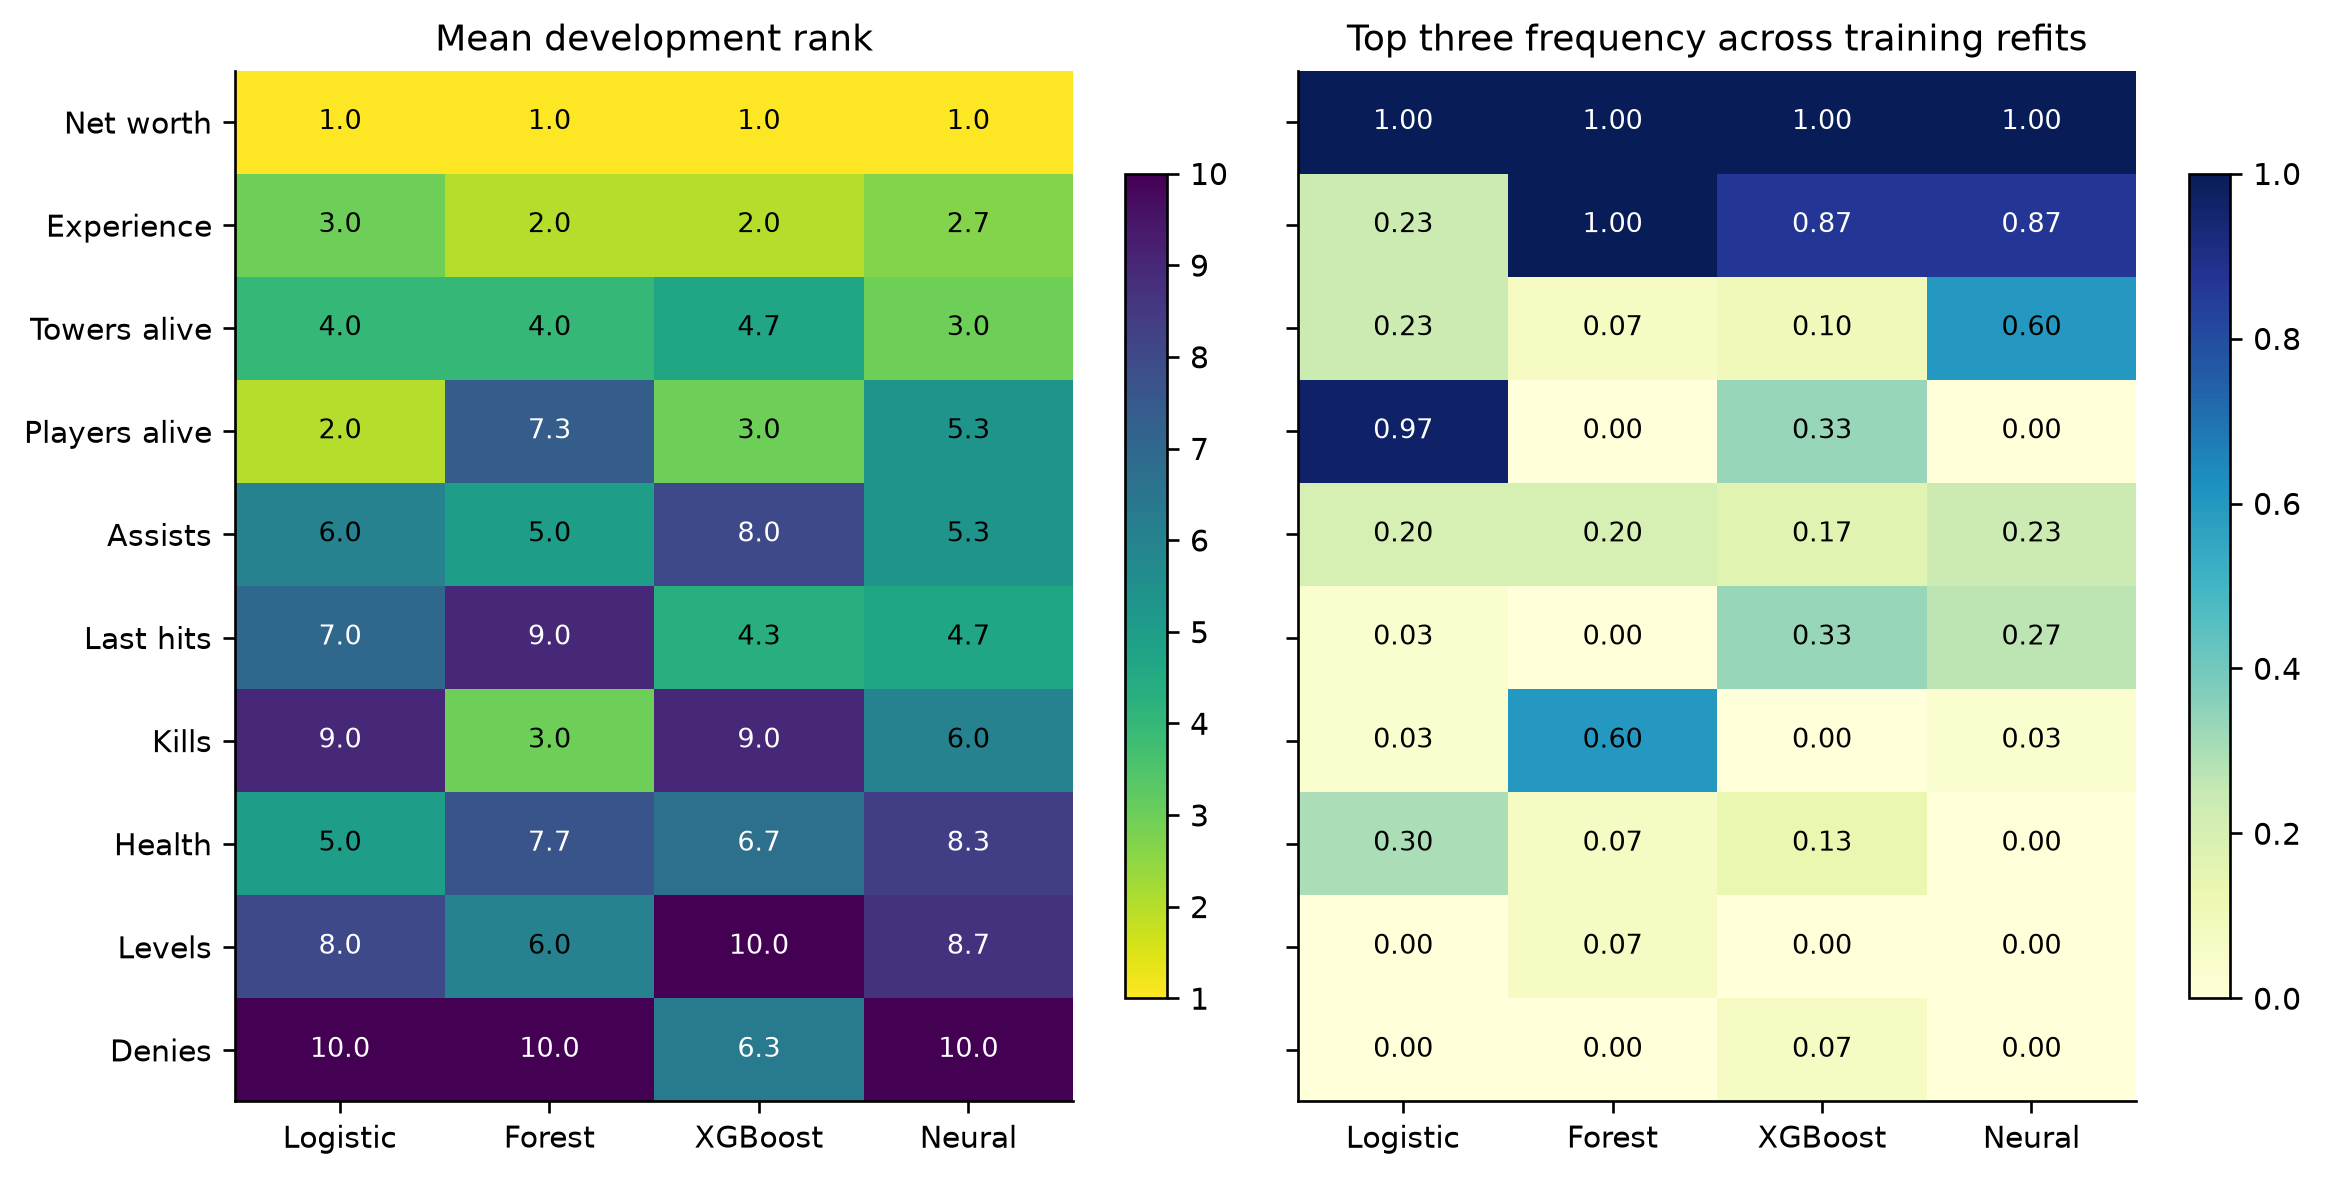

In [3]:
explanations = evidence("D_explanations.json")  # Read the actual explanation experiment and assumptions.
display(pd.Series(explanations["output_units"], name="Explanation units"))  # Prevent invalid magnitude comparisons across models.
display(pd.DataFrame(summary["development_rank_summary"]).query("horizon_seconds == 1200"))  # Show the primary development rankings across seed runs.
display(Image(filename=str(ROOT / "outputs/figures/D_rank_stability.png")))  # Compare seed ranks and actual training resample stability.

Net worth is consistently prominent. Experience, combat and survival measures can share predictive information. A correlated feature can change rank when another feature or model absorbs its signal. A low SHAP rank is not evidence that an action is strategically unimportant.

## Why use three kinds of uncertainty?

Changing the seed measures training randomness. Resampling explained matches with fixed weights measures explanation sample variation. Refitting on resampled training matches measures sensitivity to which training examples were observed. These procedures answer different questions and must not be labelled interchangeably.

In [4]:
display(pd.DataFrame(summary["seed_rank_agreement"]))  # Compare feature rank ordering between seed runs.
refits = pd.DataFrame(summary["training_refit_rank_summary"])  # Read thirty real refits per model, not resampled fixed SHAP values.
display(refits.pivot(index="feature", columns="model", values="top3_frequency").round(3))  # Show how often each feature enters the top three.
print("Refit scope:", evidence("D_refit_stability.json")["scope"])  # State the conditional design and its limits.

,horizon_seconds,model,pairwise_spearman,mean_spearman
0,600,logistic,"[1.0, 1.0, 1.0]",1.000000
1,600,neural_network,"[0.636364, 0.951515, 0.6]",0.729293
2,600,random_forest,"[0.987879, 0.975758, 0.987879]",0.983838
3,600,xgboost,"[0.987879, 0.975758, 0.951515]",0.971717
4,1200,logistic,"[1.0, 1.0, 1.0]",1.000000
5,1200,neural_network,"[0.878788, 0.866667, 0.781818]",0.842424
6,1200,random_forest,"[1.0, 0.987879, 0.987879]",0.991919
7,1200,xgboost,"[1.0, 0.975758, 0.975758]",0.983838
8,1800,logistic,"[1.0, 1.0, 1.0]",1.000000
9,1800,neural_network,"[0.987879, 0.975758, 0.951515]",0.971717


model,logistic,neural_network,random_forest,xgboost
feature,,,,
assists_diff,0.200,0.233,0.200,0.167
denies_diff,0.000,0.000,0.000,0.067
hp_diff,0.300,0.000,0.067,0.133
is_alive_diff,0.967,0.000,0.000,0.333
kills_diff,0.033,0.033,0.600,0.000
last_hits_diff,0.033,0.267,0.000,0.333
level_diff,0.000,0.000,0.067,0.000
net_worth_diff,1.000,1.000,1.000,1.000
towers_alive_diff,0.233,0.600,0.067,0.100


Refit scope: Exploratory training match bootstrap; development only; fixed estimator seed and reference background


The refits keep the estimator seed fixed and reuse a fixed validation explanation set to isolate training sample sensitivity. Thirty refits provide a descriptive stability check, not precise tail probability estimates. KPI stability remains conditional on these models, feature definitions and professional matches.

## Read the shared implementation line by line

The source below is the actual function used by the pipeline, including comments explaining what each operation does and why. `inspect` reads Python source; it does not call the function or refit a model. A function is a named sequence of reusable steps; a class groups a model's state and prediction methods. Read the comments alongside the preceding explanation, then open the source file to explore further. The frozen result record retains the original implementation fingerprints; later documentation changes do not replace that historical record.

In [5]:
import inspect  # Read implementation text without running a scientific experiment.
from IPython.display import Code  # Render Python source with readable syntax highlighting.
import dota_explanations  # Access the same shared module used by the terminal pipeline.
display(Code(inspect.getsource(dota_explanations.explain), language='python'))  # Show the commented implementation without calling it.
display(Code(inspect.getsource(dota_explanations.ranking_summary), language='python'))  # Show the commented implementation without calling it.

C:\Users\Rey\Documents\Applications\Ireland\University of Limerick\Dr Fazilat Hojaji\Sports_KPI_Self_Study\.conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


def explain(model, name, background, observations):
    """Explain the positive class with a training only reference background.

    Tree and neural explainers differ in approximation details. Their ranks
    are descriptive comparisons; their absolute numerical scales differ.
    """
    if name == "logistic":  # A linear log odds function has an analytic interventional attribution.
        scaler, linear = model[0], model[1]  # Separate the fitted transform from its coefficients.
        values = (scaler.transform(observations) - scaler.transform(background).mean(0)) * linear.coef_[0]  # Attribute each scaled feature's deviation from the training reference.
    elif name == "neural_network":  # DeepExplainer attributes the network's single output logit.
        model.network.eval()  # Disable dropout so explanations refer to a fixed prediction function.
        reference = torch.tensor(model.scaler.transform(background), dtype=torch.float32, device="cuda")  # Reuse training scaling and reference rows.
        points = torch.tensor(model.scaler.transform(observations), dtype=torch.float32, device="cuda")  # Explain only designated development observations.
        values = shap.DeepExplainer(model.network, reference).shap_values(points)  # Check additivity using SHAP's default check.
        values = np.asarray(values)[..., 0]  # Remove the singleton output axis, retaining rows and features.
    else:  # Tree models use the same observed training background rows.
        values = shap.TreeExplainer(model, data=background, feature_perturbation="interventional").shap_values(observations)  # State the interventional assumption explicitly.
        values = np.asarray(values)  # Convert the explainer output into a predictable array.
        if values.ndim == 3:  # Random Forest produces one attribution array per class.
            values = values[..., 1]  # Select Radiant win, not the opposite class.
    assert values.shape == observations.shape  # Prevent accidentally ranking outputs instead of features.
    assert np.isfinite(values).all()  # Reject invalid explanations rather than silently dropping them.
    return values  # Return one attribution for each observation and feature.

def ranking_summary(values, features, draws=1000, seed=2718):
    """Resample explained matches while holding model weights fixed."""
    magnitude = np.abs(values)  # Global importance uses mean absolute contribution, not a causal effect.
    mean = magnitude.mean(0)  # Average across the explained development matches.
    rng = np.random.default_rng(seed)  # Fix the explanation sampling bootstrap independently of training.
    ranks = []  # Collect rank vectors from resampled observed matches.
    for _ in range(draws):  # Repeat the match sampling procedure.
        index = rng.integers(0, len(values), len(values))  # Resample whole match explanation rows.
        ranks.append(rankdata(-magnitude[index].mean(0)))  # Rank larger importance first and average ties.
    ranks = np.asarray(ranks)  # Shape is bootstrap samples by features.
    return [{"feature": feature, "mean_absolute_shap": float(mean[i]), "rank": float(rankdata(-mean)[i]), "rank_95_interval": np.quantile(ranks[:, i], [.025, .975]).tolist(), "top3_frequency": float((ranks[:, i] <= 3).mean())} for i, feature in enumerate(features)]  # Keep importance, uncertainty and inclusion frequency together.